In [1]:
from datasets import load_dataset
from transformers import ViTImageProcessor
import torch

# Load CIFAR-10
dataset = load_dataset("uoft-cs/cifar10")

In [2]:

# Create ViT feature extractor from scratch (no pretrained model)
feature_extractor = ViTImageProcessor(
    do_resize=False,      # No resizing (CIFAR-10 images are already 32x32)
    do_normalize=True,
    image_mean=[0.5, 0.5, 0.5],
    image_std=[0.5, 0.5, 0.5] 
)

# Process dataset (extract features and format)
def preprocess_function(examples):
    # Preprocess images
    inputs = feature_extractor(images=examples["img"], return_tensors="pt")
    return inputs

# Apply preprocessing (same as before)
train_dataset = dataset["train"].map(preprocess_function, batched=True,remove_columns="img",num_proc=8).with_format("torch")
test_dataset = dataset["test"].map(preprocess_function, batched=True,remove_columns="img",num_proc=8).with_format("torch")

# Create PyTorch DataLoaders (same as before)
train_loader = torch.utils.data.DataLoader(
    train_dataset, 
    batch_size=4, 
    shuffle=True, 
    num_workers=8
)

test_loader = torch.utils.data.DataLoader(
    test_dataset, 
    batch_size=4, 
    shuffle=False, 
    num_workers=8
)

# Classes (same as before)
classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


In [3]:
test_dataset

Dataset({
    features: ['label', 'pixel_values'],
    num_rows: 10000
})

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


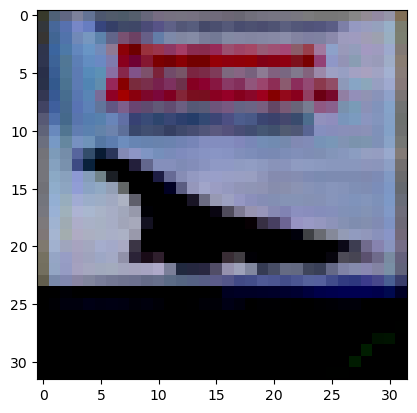

In [53]:
import numpy as np
import matplotlib.pyplot as plt


# get some random training images

samples = next(iter(test_loader))

img_plot = samples["pixel_values"][3].permute(1, 2, 0)
plt.imshow(img_plot)

In [5]:
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


net = Net()

In [6]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [12]:
for epoch in range(2):  # loop over the dataset multiple times

    running_loss = 0.0
    for i, data in enumerate(train_loader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs = data["pixel_values"]
        labels = data["label"]

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
        if i % 2000 == 1999:    # print every 2000 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0

print('Finished Training')

[1,  2000] loss: 2.167
[1,  4000] loss: 1.826
[1,  6000] loss: 1.664
[1,  8000] loss: 1.576
[1, 10000] loss: 1.528
[1, 12000] loss: 1.454
[2,  2000] loss: 1.388
[2,  4000] loss: 1.359
[2,  6000] loss: 1.348
[2,  8000] loss: 1.304
[2, 10000] loss: 1.310
[2, 12000] loss: 1.269
Finished Training


In [13]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in test_loader:
        images = data["pixel_values"]
        labels = data["label"]
        # calculate outputs by running images through the network
        outputs = net(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 53 %


In [ ]:
import torch 
from torch import nn
import torch.nn.functional as F


class AttentiveNet(nn.Module):
    def __init__(self, input_size, hidden_size) -> None:
        super().__init__()

        # self.liner1 = nn.Linear(input_size, hidden_size)
        self.cov2 = nn.Conv1d(hidden_size, hidden_size, kernel_size=3, padding=1)
        self.cov1 = nn.Conv1d(input_size, hidden_size, kernel_size=1, padding=0)
        # self.cov3 = nn.Conv1d(hidden_size, hidden_size, kernel_size=5, padding=2)
        # self.rnn = nn.LSTM(input_size, hidden_size, num_layers=2, batch_first=True, dropout=dropout, bidirectional=True)

        # self.w = nn.Parameter(torch.Tensor(hidden_size*2, 1))

        self.dense = nn.Linear(hidden_size, 1)
        

    def forward(self, x):
        x = x.permute(0,2,1).contiguous()
        x1 = self.cov1(x)
        x = self.cov2(x1)

        x = x.permute(0,2,1).contiguous()

        out = torch.mean(x, dim=1)  # [batch, 64]

        out = F.relu(out)
        out = F.sigmoid(self.dense(out))# [batch, 1]
        return out.squeeze()